# TRAK reproducibility experiment

## Reproducing TRAK’s CIFAR-10 quickstart

Fundamentals of reproducible research and free software (MVA, ENS Paris-Saclay), TP2. Salomé Fonvielle, Rémi Moysan, Jeanne Treyer.

This notebook reproduces the CIFAR-10 quickstart notebook provided by the authors of TRAK ([`examples/cifar_quickstart.ipynb`](https://github.com/MadryLab/trak/blob/main/examples/cifar_quickstart.ipynb), described in the [documentation](https://trak.readthedocs.io/en/latest/quickstart.html)). It trains a ResNet-9 on CIFAR-10, computes TRAK attribution scores, and evaluates them with the Linear Datamodeling Score (LDS).

Compared to the original notebook, we made the following additions:

Section 0 (environment setup and installation) is ours. The installation command given in the documentation fails on a current environment, so this section documents the failures and the fixes we applied, including a one-line change to the setup.py of the GPU module fast_jl.
The explanatory comments above each cell, as well as the section titles, are ours: the original notebook contains only code.

Apart from these additions, the authors’ code is run unchanged, with its default settings (one training run, 5 checkpoints, projection dimension 4,096).

Run environment: Google Colab, November 18, 2026, Tesla T4 GPU (15 GB), CUDA 13.0, Python 3.13, PyTorch 2.14.1, traker 0.3.2. No random seed is set in the original notebook, so results may vary slightly between runs.

Main results: test accuracy of 91.8%, LDS of 0.090.

## Instructions from the original notebook

Check out the quickstart tutorial: https://trak.readthedocs.io/en/latest/quickstart.html.

Use this notebook to follow along (it contains only the code from the quickstart tutorial, no comments/explanations).

We ran this notebook on a 1xA100 80G GPU. Depending on your setup, you might need to reduce the batch sizes for training & computing TRAK.

If you just want to play around with (pre-computed) TRAK scores, check out this Colab notebook instead: https://colab.research.google.com/drive/1Mlpzno97qpI3UC1jpOATXEHPD-lzn9Wg?usp=sharing.

## 0. Environment setup and installation

### 0.1 GPU check

In [ ]:
!nvidia-smi

Wed Nov 18 14:02:35 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   58C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

We check which GPU Colab gave us: a Tesla T4. Compared to the authors’ setup, two things differ:

*   Hardware: the T4 is less powerful than the A100 used by the authors, so our running times will be longer. The results themselves should not change.
*  Software: Colab uses more recent tools (CUDA 13.0). Because of this, TRAK’s GPU module does not install as is, and we had to modify one line of its code (see section 0.3).

### 0.2 Installing TRAK with the official command (fails)

We first try the installation command given in TRAK’s README and documentation (Installation FAQs): pip install traker[fast]. It fails: the GPU module fast_jl needs PyTorch to be built, but does not declare it. Recent versions of pip build each package in an isolated environment that only contains the declared dependencies, so PyTorch is missing and the build fails. As a result, nothing is installed.

In [ ]:
!pip install traker[fast] wget

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  error: subprocess-exited-with-error
  
  × Getting requirements to build wheel did not run successfully.
  │ exit code: 1
  ╰─> No available output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Getting requirements to build wheel ... error
ERROR: Failed to build 'fast_jl' when getting requirements to build wheel


We install fast_jl with --no-build-isolation, so that pip builds it in Colab’s environment, where PyTorch is already installed. This solves the first problem, but the build still fails at a later step (see next cell). We then install TRAK and wget separately, without the [fast] option, so that a failure of fast_jl does not prevent TRAK from being installed. TRAK can run without fast_jl, using a slower projection written in plain PyTorch. If fast_jl is installed later, TRAK detects and uses it automatically.

In [ ]:
!pip install --no-build-isolation fast_jl
!pip install traker wget

  Using cached fast_jl-0.1.3.tar.gz (5.3 kB)
  Preparing metadata (pyproject.toml) ... done
  error: subprocess-exited-with-error
  
  × Building wheel for fast_jl (pyproject.toml) did not run successfully.
  │ exit code: 1
  ╰─> No available output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  ERROR: Failed building wheel for fast_jl
Failed to build fast_jl
error: failed-wheel-build-for-install

× Failed to build installable wheels for some pyproject.toml based projects
╰─> fast_jl
  Using cached traker-0.3.2.tar.gz (36 kB)
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Using cached wget-3.2.zip (10 kB)
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for traker: filename=traker-0.3.2-py3-none-any.whl size=29028 sha256=c235db53df201e0aa572f465367d8fa

### 0.3 Patching and building fast_jl

#### Diagnosing the build failure

In [ ]:
!nvcc --version
!pip install -v --no-build-isolation fast_jl 2>&1 | tail -40

nvcc: NVIDIA (R) Cuda compiler driver
Copyright (c) 2005-2025 NVIDIA Corporation
Built on Wed_Aug_20_01:58:59_PM_PDT_2025
Cuda compilation tools, release 13.0, V13.0.88
Build cuda_13.0.r13.0/compiler.36424714_0
  Running command Building wheel for fast_jl (pyproject.toml)
  running bdist_wheel
  W1118 14:06:47.649000 1859 torch/utils/cpp_extension.py:786] Attempted to use ninja as the BuildExtension backend but we could not find ninja.. Falling back to using the slow distutils backend.
  running build
  running build_ext
  building 'fast_jl' extension
  creating build/temp.linux-x86_64-cpython-313
  /usr/local/cuda/bin/nvcc -I/usr/local/lib/python3.13/dist-packages/torch/include -I/usr/local/lib/python3.13/dist-packages/torch/include/torch/csrc/api/include -I/usr/local/cuda/include -I/usr/include/python3.13 -c fast_jl.cu -o build/temp.linux-x86_64-cpython-313/fast_jl.o -D__CUDA_NO_HALF_OPERATORS__ -D__CUDA_NO_HALF_CONVERSIONS__ -D__CUDA_NO_BFLOAT16_CONVERSIONS__ -D__CUDA_NO_HALF2_OPERA

The previous build failed without any message. We display the CUDA compiler version (13.0) and rerun the installation in verbose mode (-v), keeping only the last 40 lines. The cause appears: fast_jl’s setup.py hard-codes the GPU architecture 7.0 (compute_70), which CUDA 13 no longer supports (Unsupported gpu architecture 'compute_70').

#### Solving the build failure

In [ ]:
!git clone https://github.com/MadryLab/trak.git trak_repo
!sed -i 's/7.0+PTX/7.5/' trak_repo/fast_jl/setup.py
!grep TORCH_CUDA_ARCH_LIST trak_repo/fast_jl/setup.py
!cd trak_repo/fast_jl && pip install --no-build-isolation . 2>&1 | tail -5

Cloning into 'trak_repo'...
remote: Enumerating objects: 2419, done.
remote: Counting objects: 100% (366/366), done.
remote: Compressing objects: 100% (142/142), done.
remote: Total 2419 (delta 303), reused 224 (delta 224), pack-reused 2053 (from 3)
Receiving objects: 100% (2419/2419), 15.12 MiB | 18.57 MiB/s, done.
Resolving deltas: 100% (1541/1541), done.
environ['TORCH_CUDA_ARCH_LIST']="7.5"
  Created wheel for fast_jl: filename=fast_jl-0.1.3-cp313-cp313-linux_x86_64.whl size=531363 sha256=fecb5420c573bbbcc93c4a98f88551c7e70a988d58aabb21ed1c02d48b29f9bb
  Stored in directory: /tmp/pip-ephem-wheel-cache-inel2wvb/wheels/f8/1d/48/466ca25f50f23778d85d4a4f02e4f0f7e7d89446ce1b3a396e
Successfully built fast_jl


To fix the architecture problem, we download TRAK’s source code from GitHub and modify one line of fast_jl’s setup.py: the hard-coded GPU architecture 7.0 is replaced by 7.5, the architecture of our Tesla T4. The grep command checks that the change was applied. We then build and install fast_jl from this modified code, still without build isolation so that PyTorch remains available. The build now succeeds (Successfully installed fast_jl-0.1.3). This change only tells the compiler which GPU generation to target: it does not change the computations performed by TRAK.

In [ ]:
import torch
import fast_jl, trak
print("fast_jl OK")

fast_jl OK


We check that TRAK and its GPU module fast_jl can be loaded. PyTorch must be imported first: fast_jl is a compiled PyTorch extension that relies on PyTorch’s internal libraries (without it, the import fails with libc10.so: cannot open shared object file). TRAK itself always imports PyTorch first, so this is not an issue in normal use. The installation is now complete.

## 1. Training the model (authors’ notebook)


## Train and save model checkpoints

### 1.1 Imports

In [ ]:
import os
from pathlib import Path
import wget
from tqdm.auto import tqdm
import numpy as np
import torch
from torch.cuda.amp import GradScaler, autocast
from torch.nn import CrossEntropyLoss, Conv2d, BatchNorm2d
from torch.optim import SGD, lr_scheduler
import torchvision
import warnings
warnings.filterwarnings('ignore')

### 1.2 Model architecture: ResNet-9

In [ ]:
# Resnet9
class Mul(torch.nn.Module):
    def __init__(self, weight):
        super(Mul, self).__init__()
        self.weight = weight
    def forward(self, x): return x * self.weight


class Flatten(torch.nn.Module):
    def forward(self, x): return x.view(x.size(0), -1)


class Residual(torch.nn.Module):
    def __init__(self, module):
        super(Residual, self).__init__()
        self.module = module
    def forward(self, x): return x + self.module(x)


def construct_rn9(num_classes=10):
    def conv_bn(channels_in, channels_out, kernel_size=3, stride=1, padding=1, groups=1):
        return torch.nn.Sequential(
                torch.nn.Conv2d(channels_in, channels_out, kernel_size=kernel_size,
                            stride=stride, padding=padding, groups=groups, bias=False),
                torch.nn.BatchNorm2d(channels_out),
                torch.nn.ReLU(inplace=True)
        )
    model = torch.nn.Sequential(
        conv_bn(3, 64, kernel_size=3, stride=1, padding=1),
        conv_bn(64, 128, kernel_size=5, stride=2, padding=2),
        Residual(torch.nn.Sequential(conv_bn(128, 128), conv_bn(128, 128))),
        conv_bn(128, 256, kernel_size=3, stride=1, padding=1),
        torch.nn.MaxPool2d(2),
        Residual(torch.nn.Sequential(conv_bn(256, 256), conv_bn(256, 256))),
        conv_bn(256, 128, kernel_size=3, stride=1, padding=0),
        torch.nn.AdaptiveMaxPool2d((1, 1)),
        Flatten(),
        torch.nn.Linear(128, num_classes, bias=False),
        Mul(0.2)
    )
    return model

This cell defines the model to be trained: a ResNet-9, a small convolutional network with residual connections, suited to the 32×32 images of CIFAR-10. Note that “ResNet-9” is not a standardised architecture: several variants exist. The documentation points to the version of [torchskeleton](https://github.com/wbaek/torchskeleton), from which this code (kernel sizes, number of channels, the final scaling `Mul(0.2)`) is taken.

### 1.3 Data loading: CIFAR-10

In [ ]:
def get_dataloader(batch_size=256, num_workers=8, split='train', shuffle=False, augment=True):
    if augment:
        transforms = torchvision.transforms.Compose(
                        [torchvision.transforms.RandomHorizontalFlip(),
                         torchvision.transforms.RandomAffine(0),
                         torchvision.transforms.ToTensor(),
                         torchvision.transforms.Normalize((0.4914, 0.4822, 0.4465),
                                                          (0.2023, 0.1994, 0.201))])
    else:
        transforms = torchvision.transforms.Compose([
                         torchvision.transforms.ToTensor(),
                         torchvision.transforms.Normalize((0.4914, 0.4822, 0.4465),
                                                          (0.2023, 0.1994, 0.201))])

    is_train = (split == 'train')
    dataset = torchvision.datasets.CIFAR10(root='/tmp/cifar/',
                                           download=True,
                                           train=is_train,
                                           transform=transforms)

    loader = torch.utils.data.DataLoader(dataset=dataset,
                                         shuffle=shuffle,
                                         batch_size=batch_size,
                                         num_workers=num_workers)

    return loader

This function loads CIFAR-10 and serves the images in batches. For training, images are randomly flipped (data augmentation); they are also normalised with CIFAR-10’s mean and standard deviation. The dataset is downloaded from an external server (University of Toronto): in our run, this took 37 minutes. Note that RandomAffine(0) has no effect, and that num_workers=8 exceeds the 2 CPUs available on Colab, which likely explains the warnings raised later during featurization.

### 1.4 Training function

In [ ]:
def train(model, loader, lr=0.4, epochs=24, momentum=0.9,
          weight_decay=5e-4, lr_peak_epoch=5, label_smoothing=0.0, model_id=0):

    opt = SGD(model.parameters(), lr=lr, momentum=momentum, weight_decay=weight_decay)
    iters_per_epoch = len(loader)
    # Cyclic LR with single triangle
    lr_schedule = np.interp(np.arange((epochs+1) * iters_per_epoch),
                            [0, lr_peak_epoch * iters_per_epoch, epochs * iters_per_epoch],
                            [0, 1, 0])
    scheduler = lr_scheduler.LambdaLR(opt, lr_schedule.__getitem__)
    scaler = GradScaler()
    loss_fn = CrossEntropyLoss(label_smoothing=label_smoothing)

    for ep in range(epochs):
        for it, (ims, labs) in enumerate(loader):
            ims = ims.cuda()
            labs = labs.cuda()
            opt.zero_grad(set_to_none=True)
            with autocast():
                out = model(ims)
                loss = loss_fn(out, labs)

            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
            scheduler.step()
        if ep in [12, 15, 18, 21, 23]:
            torch.save(model.state_dict(), f'./checkpoints/sd_{model_id}_epoch_{ep}.pt')

    return model

This function trains the ResNet-9 for 24 epochs with SGD, using a triangular learning-rate schedule (peak of 0.4 at epoch 5) and mixed precision. Note that the paper reports a learning rate of 0.5 for CIFAR-10 (Appendix A.2), whereas this notebook uses 0.4, and that no random seed is set.

### 1.5 Training one model

In [ ]:
os.makedirs('./checkpoints', exist_ok=True)
loader_for_training = get_dataloader(batch_size=512, split='train', shuffle=True)

# you can modify the for loop below to train more models
for i in tqdm(range(1), desc='Training models..'):
    model = construct_rn9().to(memory_format=torch.channels_last).cuda()
    model = train(model, loader_for_training, model_id=i)

100%|██████████| 170M/170M [37:02<00:00, 76.7kB/s]


Training models..:   0%|          | 0/1 [00:00<?, ?it/s]

We train a single ResNet-9 (range(1)), as in the authors’ notebook, on the full CIFAR-10 training set, shuffled and augmented. Training lasts 24 epochs and saves 5 checkpoints. This cell also downloads CIFAR-10 (170 MB), which took 37 minutes in our run because of the slow external server. Training more models only requires changing range(1), at the cost of a proportionally longer running time.

### 1.6 Loading the checkpoints

In [ ]:
ckpt_files = sorted(list(Path('./checkpoints').rglob('*.pt')))
ckpts = [torch.load(ckpt, map_location='cpu') for ckpt in ckpt_files]

We reload the 5 checkpoints saved during training (epochs 12, 15, 18, 21 and 23). Each one contains the model’s weights at that point of training. TRAK will compute gradients for each of them, then average the results.

### 1.7 Checking the model’s accuracy

In [ ]:
model = construct_rn9().to(memory_format=torch.channels_last).cuda()
model.load_state_dict(ckpts[-1])
model = model.eval()

In [ ]:
loader = get_dataloader(split='val', augment=False)
model.eval()

with torch.no_grad():
    total_correct, total_num = 0., 0.
    for ims, labs in tqdm(loader):
        ims = ims.cuda()
        labs = labs.cuda()
        with autocast():
            out = model(ims)
            total_correct += out.argmax(1).eq(labs).sum().cpu().item()
            total_num += ims.shape[0]

    print(f'Accuracy: {total_correct / total_num * 100:.1f}%')

  0%|          | 0/40 [00:00<?, ?it/s]

Accuracy: 91.8%


Before running TRAK, we check that the model has learned correctly: we load the last checkpoint (epoch 23) and measure its accuracy on the 10,000 test images, which were not used for training. We obtain 91.8%, which confirms that the model is properly trained. This value may vary slightly between runs, since no random seed is set.

## 2. Running TRAK

### 2.1 Setting up TRAK

In [ ]:
batch_size = 128
loader_train = get_dataloader(batch_size=batch_size, split='train')

In [ ]:
from trak import TRAKer

traker = TRAKer(model=model,
                task='image_classification',
                proj_dim=4096,
                train_set_size=len(loader_train.dataset))

INFO:STORE:No existing model IDs in /content/trak_results.
INFO:STORE:No existing TRAK scores in /content/trak_results.


We create the TRAKer object, which computes the attribution scores. The task image_classification determines the model output function used by TRAK, as defined in the paper. Gradients will be projected to dimension k = 4,096, whereas the paper uses k = 20,000 for CIFAR-10: a smaller projection keeps less information, which may lower the attribution quality. Note also that the training images are loaded with data augmentation (random flips), so the gradients are computed on randomly flipped images, which adds noise to the scores.

### 2.2 Computing the training features (featurize)

In [ ]:
for model_id, ckpt in enumerate(tqdm(ckpts)):
    traker.load_checkpoint(ckpt, model_id=model_id)
    for batch in tqdm(loader_train):
        batch = [x.cuda() for x in batch]
        traker.featurize(batch=batch, num_samples=batch[0].shape[0])

traker.finalize_features()

  0%|          | 0/5 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7e7323fb13a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7e7323fb13a0>    
assert self._parent_pid == os.getpid(), 'can only test a child process'Traceback (most recent call last):

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
AssertionError:     can only test a child processself._shutdown_workers()

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():Exception ignored 

  0%|          | 0/391 [00:00<?, ?it/s]

    can only test a child process
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers

if w.is_alive():Exception ignored in: Exception ignored in:     Exception ignored in: Exception ignored in: 
<function _MultiProcessingDataLoaderIter.__del__ at 0x7e7323fb13a0><function _MultiProcessingDataLoaderIter.__del__ at 0x7e7323fb13a0><function _MultiProcessingDataLoaderIter.__del__ at 0x7e7323fb13a0>if w.is_alive():  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive

<function _MultiProcessingDataLoaderIter.__del__ at 0x7e7323fb13a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__

Traceback (most recent call last):


  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
      File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    Traceback (m

  0%|          | 0/391 [00:00<?, ?it/s]

  0%|          | 0/391 [00:00<?, ?it/s]

  0%|          | 0/391 [00:00<?, ?it/s]

  0%|          | 0/391 [00:00<?, ?it/s]

Finalizing features for all model IDs..: 100%|██████████| 5/5 [00:21<00:00,  4.37s/it]


For each of the 5 checkpoints, TRAK computes the gradient of each of the 50,000 training images, projects it to dimension 4,096 with the GPU module fast_jl, and stores it. finalize_features then computes the matrix (ΦᵀΦ)⁻¹ from the paper’s formula. This preparation step is done once: afterwards, any prediction can be explained without recomputing it. The AssertionError: can only test a child process messages come from the data-loading processes (num_workers=8 on a 2-CPU machine) and do not affect the results.

### 2.3 Computing the attribution scores (score)

In [ ]:
loader_targets = get_dataloader(batch_size=batch_size, split='val', augment=False)

In [ ]:
for model_id, ckpt in enumerate(tqdm(ckpts)):
    traker.start_scoring_checkpoint(exp_name='quickstart',
                                    checkpoint=ckpt,
                                    model_id=model_id,
                                    num_targets=len(loader_targets.dataset))
    for batch in loader_targets:
        batch = [x.cuda() for x in batch]
        traker.score(batch=batch, num_samples=batch[0].shape[0])

scores = traker.finalize_scores(exp_name='quickstart')

  0%|          | 0/5 [00:00<?, ?it/s]

Finalizing scores for all model IDs..: 100%|██████████| 5/5 [00:24<00:00,  4.98s/it]
INFO:STORE:Saving scores in /content/trak_results/scores/quickstart.mmap


In [ ]:
from numpy.lib.format import open_memmap
_scores = open_memmap('./trak_results/scores/quickstart.mmap')

For each checkpoint, TRAK computes the gradient of each of the 10,000 test images (without data augmentation), projects it with the same random projection as the training images, and compares it to the stored training features using the paper’s formula. finalize_scores averages the results over the 5 checkpoints, giving a 50,000 × 10,000 matrix: one score for each (training image, test image) pair. The scores are saved to disk and can be reloaded with open_memmap. Note that the soft-thresholding step of the paper’s algorithm is not applied.

## 3. Visualising the results

In [ ]:
from matplotlib import pyplot as plt

In [ ]:
ds_train = torchvision.datasets.CIFAR10(root='/tmp/cifar/', download=True, train=True)
ds_val = torchvision.datasets.CIFAR10(root='/tmp/cifar/', download=True, train=False)

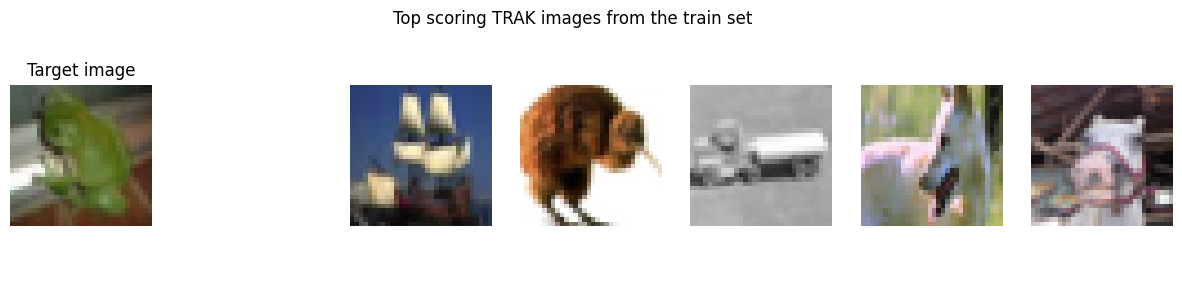

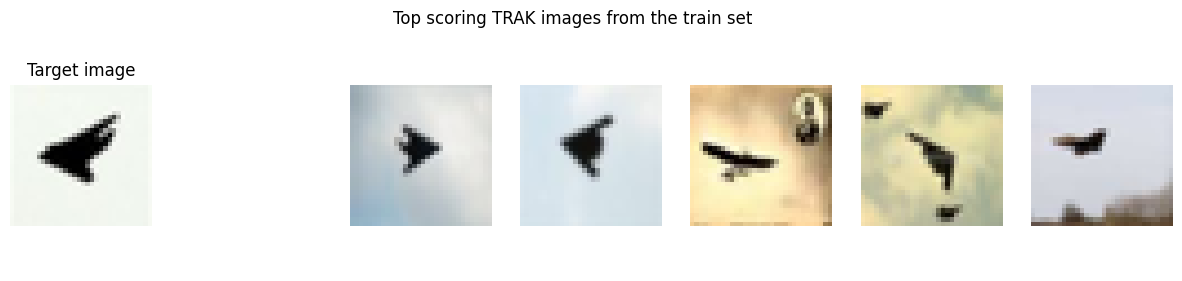

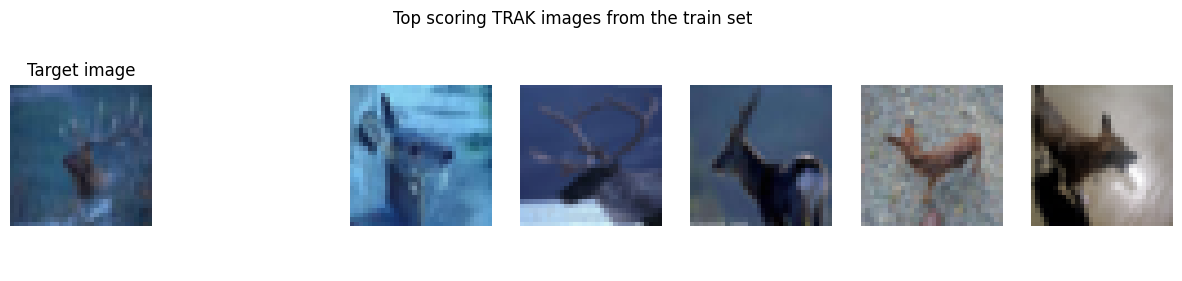

In [ ]:
for i in [7, 21, 22]:

    fig, axs = plt.subplots(ncols=7, figsize=(15, 3))
    fig.suptitle('Top scoring TRAK images from the train set')

    axs[0].imshow(ds_val[i][0])

    axs[0].axis('off'); axs[0].set_title('Target image')
    axs[1].axis('off')

    top_trak_scorers = scores[:, i].argsort()[-5:][::-1]
    for ii, train_im_ind in enumerate(top_trak_scorers):
        axs[ii + 2].imshow(ds_train[train_im_ind][0]); axs[ii + 2].axis('off')

    fig.show()

You can also explore TRAK scores computed for CIFAR-10 from multiple independently-trained models (10, 100, 1000 models) in this [colab notebook](https://colab.research.google.com/drive/1Mlpzno97qpI3UC1jpOATXEHPD-lzn9Wg?usp=sharing).

For three test images chosen by the authors, we display the 5 training images with the highest TRAK scores. For the airplane and the deer, the most influential images are mostly of the same class and visually similar, which is consistent. For the frog, none of the top images is a frog: either the model misclassifies this image, or the scores are noisy because they come from a single training run, which is consistent with the low LDS obtained below.

## 4. Evaluating the attribution quality (LDS)


*From the original notebook:* We exactly follow the steps in https://docs.ffcv.io/ffcv_examples/cifar10.html. Additionally, we train on *subsets* of CIFAR-10, parametrized by the `masks` arrays below. We collect the model outputs for each retraining on a different subset (mask) in a separate array `margins`.

We train a total of 10,000 models. Note that this is not necessary to get TRAK scores. This step is only necessary to get (very high quality) LDS correlation estimates.

In [ ]:
from scipy.stats import spearmanr

In [ ]:
def eval_correlations(scores, tmp_path):
    masks_url = 'https://www.dropbox.com/s/x76uyen8ffkjfke/mask.npy?dl=1'
    margins_url = 'https://www.dropbox.com/s/q1dxoxw78ct7c27/val_margins.npy?dl=1'

    masks_path = Path(tmp_path).joinpath('mask.npy')
    wget.download(masks_url, out=str(masks_path), bar=None)
    # num masks, num train samples
    masks = torch.as_tensor(np.load(masks_path, mmap_mode='r')).float()

    margins_path = Path(tmp_path).joinpath('val_margins.npy')
    wget.download(margins_url, out=str(margins_path), bar=None)
    # num , num val samples
    margins = torch.as_tensor(np.load(margins_path, mmap_mode='r'))

    val_inds = np.arange(10_000)
    preds = masks @ scores
    rs = []
    ps = []
    for ind, j in tqdm(enumerate(val_inds)):
        r, p = spearmanr(preds[:, ind], margins[:, j])
        rs.append(r)
        ps.append(p)
    rs, ps = np.array(rs), np.array(ps)
    print(f'Correlation: {rs.mean():.3f} (avg p value {ps.mean():.6f})')
    return rs.mean()

In [ ]:
corr = eval_correlations(scores, '.')

0it [00:00, ?it/s]

Correlation: 0.090 (avg p value 0.003009)


An LDS of 0.090 indicates a weak but statistically significant positive correlation between TRAK’s predictions and the actual effect of removing training data. It is consistent with the main figure of the paper: for ResNet-9 on CIFAR-10, TRAK’s LDS ranges from about 0.06 for the cheapest setting to about 0.54 for the most expensive one, and our value lies between the two cheapest settings. It is also above the threshold expected by the authors’ own tests for a few checkpoints (0.05).